# 오차와 오차의 측정

In [1]:
# MAE
from sklearn.metrics import mean_absolute_error
import numpy as np

y = np.array([1, 2, 3, 4, 5])
y_hat = np.array([1.2, 2.4, 2.5, 4.6, 5.4])
diff = mean_absolute_error(y, y_hat)
print('MAE:', diff)

MAE: 0.41999999999999993


In [3]:
# MSE
from sklearn.metrics import mean_squared_error

y = np.array([1, 2, 3, 4, 5])
y_hat = np.array([1.2, 2.4, 2.5, 4.6, 5.4])
diff = mean_squared_error(y, y_hat)
print('MSE:', diff)

MSE: 0.19399999999999995


# 사이킷런 선형회귀

In [15]:
# 라이브러리 임포트
import numpy as np
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
x = [[163], [179], [166], [169], [171]]
y = [54, 63, 57, 56, 58]

lr.fit(x, y)

LinearRegression()

In [16]:
coef = lr.coef_ # 기울기
intercept = lr.intercept_ # 절편
score = lr.score(x, y) # 학습된 직선이 데이터를 얼마나 잘 따르는가?
print(coef)

print(f'y = {coef[0]:.2f}X + {intercept:.2f}')
print('score:', round(score, 3))

[0.53125]
y = 0.53X + -32.50
score: 0.919


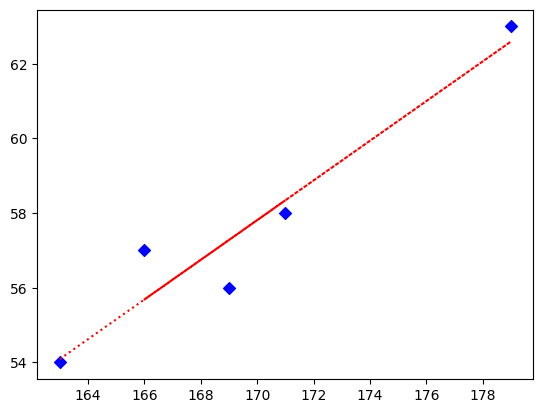

In [18]:
# 시각화
import matplotlib.pyplot as plt

plt.scatter(x, y, color='blue', marker='D')
y_pred = lr.predict(x)
plt.plot(x, y_pred, 'r:')
plt.show()

## 오차곡면 구하기

In [19]:
X = np.array([1, 4.5, 9, 10, 13])
y = np.array([0, 0.2, 2.5, 5.4, 7.3])

w, b = 0, 0
learning_rate, epoch = 0.005, 1000
n = len(X)

for i in range(epoch):
    y_pred = w*X + b
    error = y_pred - y
    w -= learning_rate * (error * X).sum()
    b -= learning_rate * error.sum()

print(f'w: {w:.2f}, b: {b:.2f}')

w: 0.63, b: -1.65


In [ ]:
X = np.array([1, 4.5, 9, 10, 13])
y = np.array([0, 0.2, 2.5, 5.4, 7.3])

w, b = 0, 0
learning_rate, epoch = 1.0, 1000
n = len(X)

for i in range(epoch):
    y_pred = w*X + b
    error = y_pred - y
    w -= learning_rate * (error * X).sum()
    b -= learning_rate * error.sum()

print(f'w: {w:.2f}, b: {b:.2f}')
# 발산!

w: nan, b: nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/tmp/ipykernel_55246/4147643277.py:11: RuntimeWarning: invalid value encountered in scalar subtract
  w -= learning_rate * (error * X).sum()


In [22]:
X = np.array([1, 4.5, 9, 10, 13])
y = np.array([0, 0.2, 2.5, 5.4, 7.3])

w, b = 0, 0
learning_rate, epoch = 1e-5, 1000
n = len(X)

for i in range(epoch):
    y_pred = w*X + b
    error = y_pred - y
    w -= learning_rate * (error * X).sum()
    b -= learning_rate * error.sum()

print(f'w: {w:.2f}, b: {b:.2f}')

w: 0.45, b: 0.03


In [25]:
def grad(learning_rate, epoch):
    X = np.array([1, 4.5, 9, 10, 13])
    y = np.array([0, 0.2, 2.5, 5.4, 7.3])

    w, b = 0, 0

    n = len(X)

    for i in range(epoch):
        y_pred = w*X + b
        error = y_pred - y
        w -= learning_rate * (error * X).sum()
        b -= learning_rate * error.sum()

    return w, b

print('학습률이 너무 클 때')
w, b = grad(1.0, 1000)
print(f'w: {w}, b: {b}')

print('학습률이 너무 작을 때')
w, b = grad(1e-5, 1000)
print(f'w: {w:.2f}, b: {b:.2f}')

학습률이 너무 클 때
w: nan, b: nan
학습률이 너무 작을 때
w: 0.45, b: 0.03


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/tmp/ipykernel_55246/2550109307.py:12: RuntimeWarning: invalid value encountered in scalar subtract
  w -= learning_rate * (error * X).sum()


In [26]:
# 정규화
import numpy as np

yr = np.array([15, 30, 23, 5, 9, 43, 33, 29, 3, 56])
n_rooms = np.array([2, 4, 3, 4, 4, 3, 3, 1, 1, 2])

print(f'정규화 이전의 yr: {yr}')
sz = np.max(yr) - np.min(yr)
np.set_printoptions(precision=2) # 출력의 정밀도 설정
print(f'정규화 이후의 yr: {((yr - np.min(yr))/sz)}')

print(f'정규화 이전의 n_rooms: {n_rooms}')
sz = np.max(n_rooms) - np.min(n_rooms)
print(f'정규화 이후의 n_rooms: {((n_rooms - np.min(n_rooms))/sz)}')

정규화 이전의 yr: [15 30 23  5  9 43 33 29  3 56]
정규화 이후의 yr: [0.23 0.51 0.38 0.04 0.11 0.75 0.57 0.49 0.   1.  ]
정규화 이전의 n_rooms: [2 4 3 4 4 3 3 1 1 2]
정규화 이후의 n_rooms: [0.33 1.   0.67 1.   1.   0.67 0.67 0.   0.   0.33]


In [27]:
# 표준화
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# 표준화 데이터를 생성함
yr_scaled_d = scaler.fit_transform(yr[:, np.newaxis])
print(f'표준화 이전의 yr: {yr}')
np.set_printoptions(precision=2)
print(f'표준화 이후의 yr: {yr_scaled_d}')

표준화 이전의 yr: [15 30 23  5  9 43 33 29  3 56]
표준화 이후의 yr: [[-0.59]
 [ 0.33]
 [-0.1 ]
 [-1.21]
 [-0.96]
 [ 1.13]
 [ 0.52]
 [ 0.27]
 [-1.33]
 [ 1.94]]
